In [100]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import yfinance as yf

print("MarketPulse is ready!")

MarketPulse is ready!


In [101]:
tickers = ["AAPL", "MSFT", "NVDA", "SPY"]

data = yf.download(
    tickers,
    period="2y",
    interval="1d",
    auto_adjust=True,
    progress=False
)["Close"]

print(data.head())

Ticker            AAPL        MSFT        NVDA         SPY
Date                                                      
2024-11-14  226.403717  420.251343  146.367279  579.965881
2024-11-15  223.209335  408.546173  141.600021  572.537292
2024-11-18  226.205292  409.294434  139.774933  574.883240
2024-11-19  226.463226  411.292847  146.616592  576.984741
2024-11-20  227.177490  409.028595  145.499588  577.180176


In [102]:
print("Dataset shape:", data.shape)

print("\nMissing values:")
print(data.isnull().sum())

print("\nDataset information:")
print(data.describe())

Dataset shape: (501, 4)

Missing values:
Ticker
AAPL    0
MSFT    0
NVDA    0
SPY     0
dtype: int64

Dataset information:
Ticker        AAPL        MSFT        NVDA         SPY
count   501.000000  501.000000  501.000000  501.000000
mean    260.451535  450.180540  173.906021  659.417625
std      43.166365   52.511931   34.974728   72.384668
min     171.235855  350.446075   94.072754  488.379059
25%     228.030670  403.564575  141.570129  591.734924
50%     255.730286  448.694611  180.567474  662.077026
75%     291.107544  500.125153  199.866348  732.481079
max     356.269989  555.799988  239.240005  779.090027


In [103]:
print("First date:", data.index.min())
print("Last date:", data.index.max())
print("Number of trading days:", len(data))

First date: 2024-11-14 00:00:00
Last date: 2026-11-13 00:00:00
Number of trading days: 501


In [104]:
daily_returns = data.pct_change().dropna()

print(daily_returns.head())

Ticker          AAPL      MSFT      NVDA       SPY
Date                                              
2024-11-15 -0.014109 -0.027853 -0.032571 -0.012809
2024-11-18  0.013422  0.001832 -0.012889  0.004097
2024-11-19  0.001140  0.004883  0.048948  0.003656
2024-11-20  0.003154 -0.005505 -0.007619  0.000339
2024-11-21 -0.002096 -0.004317  0.005347  0.005368


In [105]:
daily_returns = data.pct_change().dropna()

print(daily_returns.tail())

Ticker          AAPL      MSFT      NVDA       SPY
Date                                              
2026-11-09  0.024301  0.027459 -0.042703  0.023664
2026-11-10 -0.006216 -0.022048 -0.054738 -0.003680
2026-11-11  0.020430 -0.022564  0.028658  0.013188
2026-11-12 -0.001351  0.003588 -0.043401 -0.003540
2026-11-13  0.003917  0.001683 -0.020097 -0.003632


In [106]:
average_returns = daily_returns.mean()

volatility = daily_returns.std()

summary = pd.DataFrame({
    "Average Daily Return": average_returns,
    "Daily Volatility": volatility
})

print(summary)

        Average Daily Return  Daily Volatility
Ticker                                        
AAPL                0.001073          0.018277
MSFT                0.000611          0.018605
NVDA                0.000610          0.028160
SPY                 0.000582          0.010637


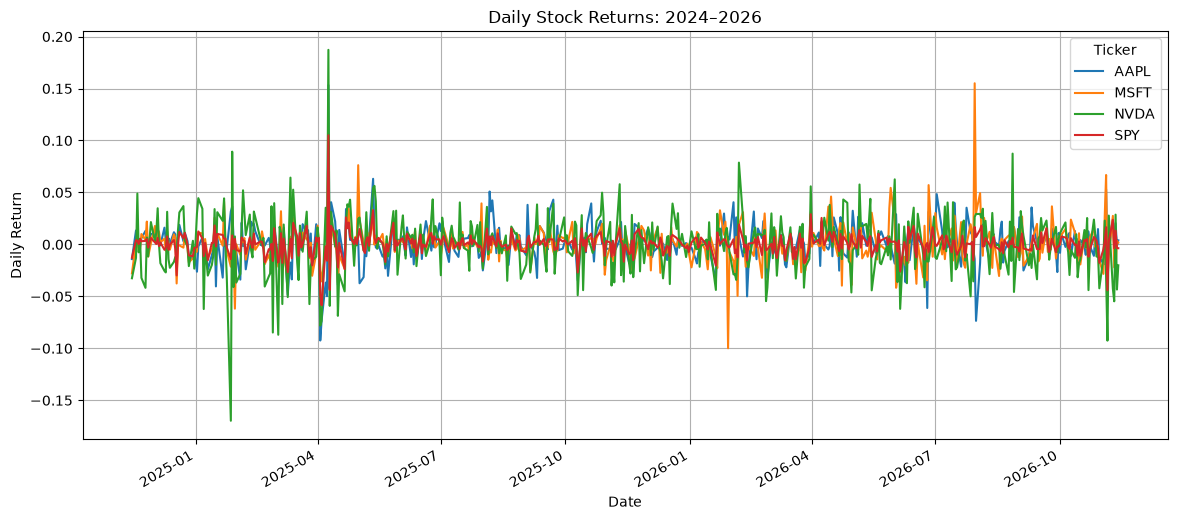

In [107]:
daily_returns.plot(
    figsize=(14, 6),
    title="Daily Stock Returns: 2024–2026"
)

plt.xlabel("Date")
plt.ylabel("Daily Return")
plt.legend(title="Ticker")
plt.grid(True)
plt.show()

In [108]:
correlation = daily_returns.corr()

print(correlation.round(3))

Ticker   AAPL   MSFT   NVDA    SPY
Ticker                            
AAPL    1.000  0.314  0.286  0.610
MSFT    0.314  1.000  0.402  0.537
NVDA    0.286  0.402  1.000  0.691
SPY     0.610  0.537  0.691  1.000


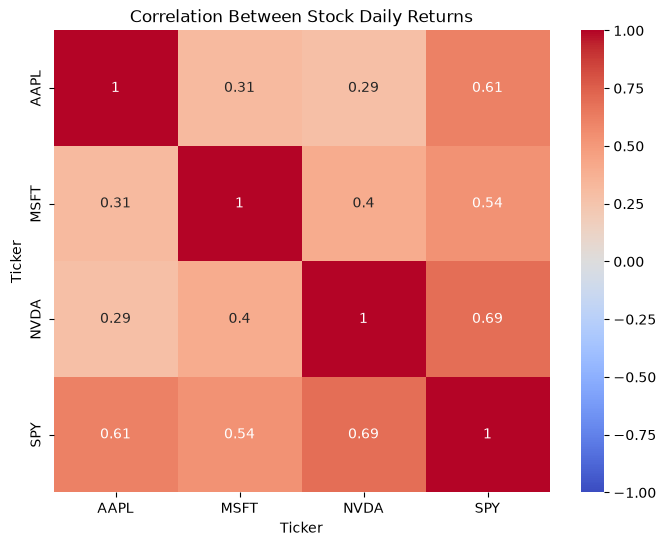

In [109]:
import seaborn as sns

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Between Stock Daily Returns")
plt.show()

In [110]:
initial_investment = 1000

normalized_prices = data / data.iloc[0]

investment_values = normalized_prices * initial_investment

print(investment_values.tail())

Ticker             AAPL         MSFT         NVDA          SPY
Date                                                          
2026-11-09  1547.782612  1297.271269  1220.696315  1297.817728
2026-11-10  1538.161106  1268.669291  1153.878110  1293.041551
2026-11-11  1569.585473  1240.043640  1186.945585  1310.094304
2026-11-12  1567.465453  1244.493347  1135.431385  1305.456096
2026-11-13  1573.604858  1246.587343  1112.612103  1300.714437


In [111]:
total_returns = (
    investment_values.iloc[-1] / initial_investment - 1
) * 100

print(total_returns.sort_values(ascending=False).round(2))

Ticker
AAPL    57.36
SPY     30.07
MSFT    24.66
NVDA    11.26
Name: 2026-11-13 00:00:00, dtype: float64


In [112]:
annualized_returns = daily_returns.mean() * 252

annualized_volatility = daily_returns.std() * np.sqrt(252)

risk_summary = pd.DataFrame({
    "Annualized Return": annualized_returns,
    "Annualized Volatility": annualized_volatility
})

print((risk_summary * 100).round(2))

        Annualized Return  Annualized Volatility
Ticker                                          
AAPL                27.03                  29.01
MSFT                15.40                  29.54
NVDA                15.38                  44.70
SPY                 14.67                  16.89


In [113]:
forecast = daily_returns.rolling(window=20).mean()

latest_forecast = forecast.iloc[-1]

print("Estimated next-day returns:")
print((latest_forecast * 100).round(3))

Estimated next-day returns:
Ticker
AAPL    0.201
MSFT   -0.024
NVDA   -1.306
SPY    -0.049
Name: 2026-11-13 00:00:00, dtype: float64


In [114]:
predictions = daily_returns.shift(1).rolling(window=20).mean()

comparison = pd.DataFrame({
    "Actual": daily_returns.stack(),
    "Predicted": predictions.stack()
}).dropna()

print(comparison.head(10))

                     Actual  Predicted
Date       Ticker                     
2024-12-16 AAPL    0.011728   0.004217
           MSFT    0.009659   0.002495
           NVDA   -0.016760  -0.004154
           SPY     0.004270   0.000919
2024-12-17 AAPL    0.009720   0.005509
           MSFT    0.006355   0.004370
           NVDA   -0.012197  -0.003364
           SPY    -0.004120   0.001773
2024-12-18 AAPL   -0.021422   0.005323
           MSFT   -0.037561   0.004596


In [115]:
comparison["Error"] = (
    comparison["Actual"] - comparison["Predicted"]
)

mae = comparison["Error"].abs().groupby(
    level="Ticker"
).mean()

print("Mean Absolute Error:")
print((mae * 100).round(3))

Mean Absolute Error:
Ticker
AAPL    1.288
MSFT    1.301
NVDA    2.095
SPY     0.721
Name: Error, dtype: float64


In [116]:
yearly_returns = (
    data.resample("YE").last()
    / data.resample("YE").first()
    .shift(1) - 1
) * 100

print(yearly_returns.round(2))

Ticker       AAPL   MSFT   NVDA    SPY
Date                                  
2024-12-31    NaN    NaN    NaN    NaN
2025-12-31  19.66  14.35  27.12  16.67
2026-12-31  47.27  26.88  18.05  31.57


In [117]:
yearly_volatility = (
    daily_returns.groupby(daily_returns.index.year).std()
    * np.sqrt(252) * 100
)

print(yearly_volatility.round(2))


Ticker   AAPL   MSFT   NVDA    SPY
Date                              
2024    15.19  19.88  36.35  12.86
2025    32.51  24.26  49.62  19.49
2026    26.18  35.63  39.63  13.99


In [118]:
yearly_performance = (
    (1 + daily_returns)
    .groupby(daily_returns.index.year)
    .prod()
    .sub(1) * 100
)

print(yearly_performance.round(2))

Ticker   AAPL   MSFT   NVDA    SPY
Date                              
2024     9.73  -1.06  -8.49  -0.89
2025     9.05  15.58  38.92  17.72
2026    31.51   9.01 -12.48  11.49


In [119]:
risk_adjusted = yearly_performance / yearly_volatility

print("Annual Return-to-Volatility Ratio:")
print(risk_adjusted.round(3))

Annual Return-to-Volatility Ratio:
Ticker   AAPL   MSFT   NVDA    SPY
Date                              
2024    0.640 -0.054 -0.234 -0.069
2025    0.278  0.642  0.784  0.909
2026    1.203  0.253 -0.315  0.821


In [120]:
scorecard = pd.concat({
    "Annual Return (%)": yearly_performance,
    "Annualized Volatility (%)": yearly_volatility,
    "Return/Volatility Ratio": risk_adjusted
}, axis=1)

print(scorecard.round(2))

       Annual Return (%)                      Annualized Volatility (%)  \
Ticker              AAPL   MSFT   NVDA    SPY                      AAPL   
Date                                                                      
2024                9.73  -1.06  -8.49  -0.89                     15.19   
2025                9.05  15.58  38.92  17.72                     32.51   
2026               31.51   9.01 -12.48  11.49                     26.18   

                            Return/Volatility Ratio                    
Ticker   MSFT   NVDA    SPY                    AAPL  MSFT  NVDA   SPY  
Date                                                                   
2024    19.88  36.35  12.86                    0.64 -0.05 -0.23 -0.07  
2025    24.26  49.62  19.49                    0.28  0.64  0.78  0.91  
2026    35.63  39.63  13.99                    1.20  0.25 -0.31  0.82  


In [121]:
difference = (
    yearly_accuracy["Model_MAE"]
    - yearly_accuracy["Zero_Forecast_MAE"]
)

percentage_worse = (
    difference / yearly_accuracy["Zero_Forecast_MAE"]
) * 100

print("Percentage worse than baseline:")
print(percentage_worse.round(2))


Percentage worse than baseline:
Year
2024    1.96
2025    3.34
2026    2.56
dtype: float64


In [122]:
features = pd.DataFrame(index=daily_returns.index)

features["Previous_Day_Return"] = daily_returns["AAPL"].shift(1)

features["Five_Day_Average"] = daily_returns["AAPL"].rolling(5).mean().shift(1)

features["Twenty_Day_Average"] = daily_returns["AAPL"].rolling(20).mean().shift(1)

features["Twenty_Day_Volatility"] = daily_returns["AAPL"].rolling(20).std().shift(1)

features["SPY_Previous_Return"] = daily_returns["SPY"].shift(1)

target = daily_returns["AAPL"]

model_data = features.copy()
model_data["Target"] = target

model_data = model_data.dropna()

print(model_data.head())

            Previous_Day_Return  Five_Day_Average  Twenty_Day_Average  \
Date                                                                    
2024-12-16             0.000686          0.004344            0.004217   
2024-12-17             0.011728          0.003469            0.005509   
2024-12-18             0.009720          0.004586            0.005323   
2024-12-19            -0.021422          0.001335            0.004195   
2024-12-20             0.007015          0.001545            0.004388   

            Twenty_Day_Volatility  SPY_Previous_Return    Target  
Date                                                              
2024-12-16               0.007375            -0.000198  0.011728  
2024-12-17               0.006158             0.004270  0.009720  
2024-12-18               0.005960            -0.004120 -0.021422  
2024-12-19               0.008421            -0.029803  0.007015  
2024-12-20               0.008440            -0.000307  0.018816  


In [123]:
from sklearn.model_selection import train_test_split

X = model_data.drop(columns=["Target"])
y = model_data["Target"]

split_index = int(len(model_data) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))

print("Training period:", X_train.index.min(), "to", X_train.index.max())
print("Testing period:", X_test.index.min(), "to", X_test.index.max())

Training observations: 384
Testing observations: 96
Training period: 2024-12-16 00:00:00 to 2026-06-30 00:00:00
Testing period: 2026-07-01 00:00:00 to 2026-11-13 00:00:00


In [124]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train, y_train)

predictions = model.predict(X_test)

print("Model training complete!")
print("Number of predictions:", len(predictions))


Model training complete!
Number of predictions: 96


In [125]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

linear_mae = mean_absolute_error(y_test, predictions)

linear_rmse = np.sqrt(
    mean_squared_error(y_test, predictions)
)

baseline_mae = mean_absolute_error(
    y_test,
    np.zeros(len(y_test))
)

print("Linear Regression MAE:", round(linear_mae * 100, 3), "%")
print("Linear Regression RMSE:", round(linear_rmse * 100, 3), "%")
print("Zero Forecast MAE:", round(baseline_mae * 100, 3), "%")


Linear Regression MAE: 1.197 %
Linear Regression RMSE: 1.639 %
Zero Forecast MAE: 1.206 %


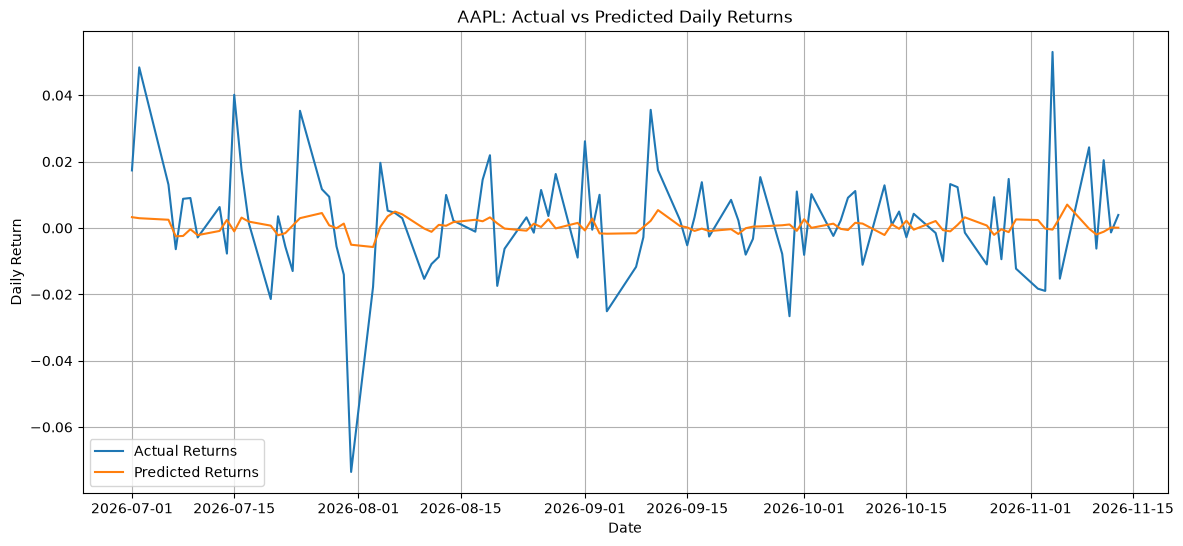

In [126]:
plt.figure(figsize=(14, 6))

plt.plot(y_test.index, y_test, label="Actual Returns")
plt.plot(y_test.index, predictions, label="Predicted Returns")

plt.title("AAPL: Actual vs Predicted Daily Returns")
plt.xlabel("Date")
plt.ylabel("Daily Return")
plt.legend()
plt.grid(True)

plt.show()

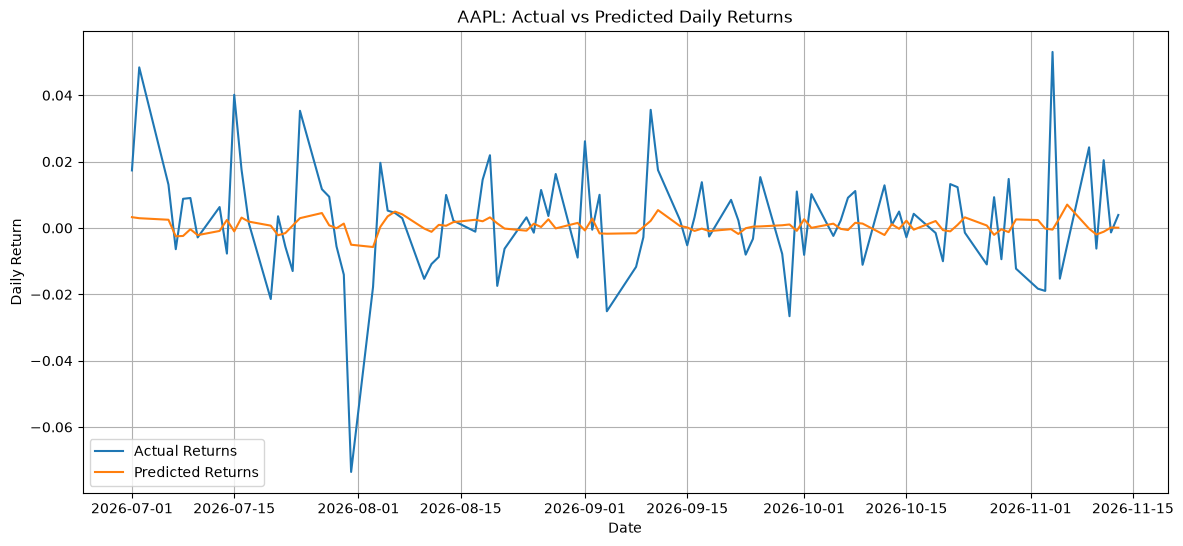

In [127]:
plt.figure(figsize=(14, 6))

plt.plot(y_test.index, y_test, label="Actual Returns")
plt.plot(y_test.index, predictions, label="Predicted Returns")

plt.title("AAPL: Actual vs Predicted Daily Returns")
plt.xlabel("Date")
plt.ylabel("Daily Return")
plt.legend()
plt.grid(True)

plt.show()

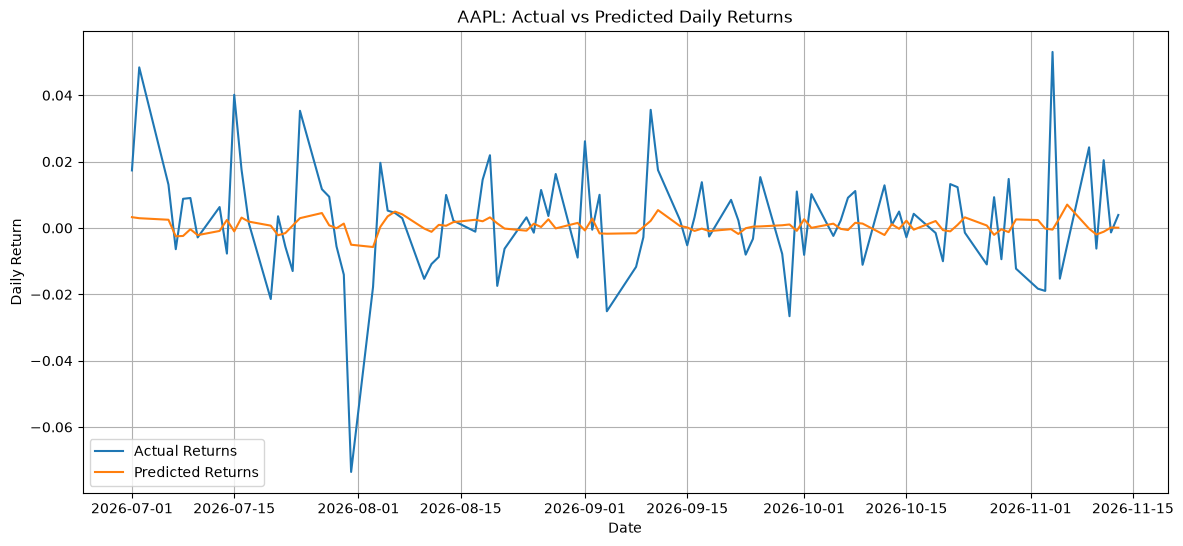

In [128]:
plt.figure(figsize=(14, 6))

plt.plot(y_test.index, y_test, label="Actual Returns")
plt.plot(y_test.index, predictions, label="Predicted Returns")

plt.title("AAPL: Actual vs Predicted Daily Returns")
plt.xlabel("Date")
plt.ylabel("Daily Return")
plt.legend()
plt.grid(True)

plt.show()

In [129]:
improvement = (baseline_mae - linear_mae) / baseline_mae * 100

print(f"MAE improvement over baseline: {improvement:.2f}%")


MAE improvement over baseline: 0.68%


In [130]:
directional_accuracy = (
    np.sign(predictions) == np.sign(y_test)
).mean() * 100

print(f"Directional Accuracy: {directional_accuracy:.2f}%")

Directional Accuracy: 45.83%


In [131]:
print("MARKETPULSE — MODEL EVALUATION")
print("--------------------------------")
print("Stock: AAPL")
print("Model: Linear Regression")
print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))
print()
print(f"Linear Regression MAE: {linear_mae * 100:.3f}%")
print(f"Zero Forecast MAE: {baseline_mae * 100:.3f}%")
print(f"MAE Improvement: {improvement:.2f}%")
print(f"Directional Accuracy: {directional_accuracy:.2f}%")
print()
print("Conclusion:")
print("The model slightly outperformed the zero-return baseline")
print("in prediction error, but struggled to predict market direction.")


MARKETPULSE — MODEL EVALUATION
--------------------------------
Stock: AAPL
Model: Linear Regression
Training observations: 384
Testing observations: 96

Linear Regression MAE: 1.197%
Zero Forecast MAE: 1.206%
MAE Improvement: 0.68%
Directional Accuracy: 45.83%

Conclusion:
The model slightly outperformed the zero-return baseline
in prediction error, but struggled to predict market direction.
